In [8]:
import arcgis_geometry, arcgis
from arcgis.geometry import Geometry
from IPython.display import display

In [9]:
sr_from = {'wkid': 102100, 'latestWkid': 3857}
sr_to = {'wkid':6424}
polygon = arcgis_geometry.Geometry({'spatialReference': {'wkid': 102100, 'latestWkid': 3857},
 'rings': [[[-9159430.78506556, 4224257.59908715],
   [-9159427.00020381, 4224301.87053329],
   [-9159420.32103382, 4224332.61469815],
   [-9159400, 4224300]]]})
polyline = arcgis_geometry.Geometry({'paths': [[[-9159430.78506556, 4224257.59908715],
   [-9159427.00020381, 4224301.87053329],
   [-9159420.32103382, 4224332.61469815]]],
 'spatialReference': {'wkid': 102100, 'latestWkid': 3857}})
multipoint = arcgis_geometry.Geometry({'points': [[-9159430.78506556, 4224257.59908715],
   [-9159427.00020381, 4224301.87053329],
   [-9159420.32103382, 4224332.61469815]],
 'spatialReference': {'wkid': 102100, 'latestWkid': 3857}})
point = arcgis_geometry.Geometry({'x': -9159430.78506556, 'y':  4224257.59908715, 'spatialReference': {'wkid': 102100, 'latestWkid': 3857}})
collection = [polygon, polyline, multipoint, point]

In [10]:
sr = arcgis_geometry.SpatialReference(sr_from)
sr.wkid
sr.latest_wkid
str(sr)

'{"wkid":102100,"latestWkid":3857}'

In [11]:
[[[elt for elt in coord] for coord in ring] for ring in polygon.rings]

[[[-9159430.78506556, 4224257.59908715],
  [-9159427.00020381, 4224301.87053329],
  [-9159420.32103382, 4224332.61469815],
  [-9159400.0, 4224300.0]]]

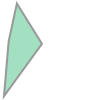

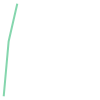

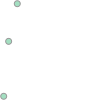

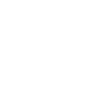

In [12]:
for x in collection:
    display(Geometry(str(x)))

In [13]:
transformations = arcgis_geometry.projection.get_transformations(sr_from, sr_to, collection[0].extent())
transformations

wkid: Some(3857)
v_wkid: None
out_wkid: Ok(Some(SpatialReference { baseGeographic: Some(SpatialReference { hasVertical: false, isGeographic: true, isPannable: true, isProjected: false, resolution: 1e-9, tolerance: 8.983152841195215e-9, verticalResolution: 0.0001, verticalTolerance: 0.001, verticalWKID: 0, WKID: 4326, WKText: "GEOGCS[\"GCS_WGS_1984\",DATUM[\"D_WGS_1984\",SPHEROID[\"WGS_1984\",6378137.0,298.257223563]],PRIMEM[\"Greenwich\",0.0],UNIT[\"Degree\",0.0174532925199433]]", .. }), hasVertical: false, isGeographic: false, isPannable: true, isProjected: true, resolution: 0.0001, tolerance: 0.001, unit: UnitOwned { abbreviation: "m", displayName: "Meter", name: "Meter", objectType: LinearUnit, pluralDisplayName: "Meters", WKID: 9001 }, verticalResolution: 0.0001, verticalTolerance: 0.001, verticalUnit: None, verticalWKID: 0, WKID: 3857, WKText: "PROJCS[\"WGS_1984_Web_Mercator_Auxiliary_Sphere\",GEOGCS[\"GCS_WGS_1984\",DATUM[\"D_WGS_1984\",SPHEROID[\"WGS_1984\",6378137.0,298.2572235

[WGS_1984_(ITRF08)_To_NAD_1983_2011,
 WGS_1984_(ITRF00)_To_NAD_1983_2011,
 ~ITRF_2000_To_WGS_1984 + ITRF_2000_To_NAD_1983_2011,
 ~NAD_1983_(2011)_to_WGS_1984_1,
 WGS_1984_(ITRF00)_To_NAD_1983_CORS96 + NAD_1983_CORS96_To_NAD_1983_2011,
 WGS_1984_(ITRF00)_To_NAD_1983_HARN + NAD_1983_HARN_To_NAD_1983_2011,
 ~NAD_1983_HARN_To_WGS_1984 + NAD_1983_HARN_To_NAD_1983_2011,
 ~NAD_1983_NSRS2007_To_WGS_1984_1 + NAD_1983_NSRS2007_To_NAD_1983_2011,
 ~NAD_1983_NSRS2007_To_WGS_1984_1 + NAD_1983_NSRS2007_To_2011_NADCON5_3D_CONUS_1,
 ~NAD_1983_HARN_To_WGS_1984_2 + NAD_1983_HARN_To_NAD_1983_2011,
 ~NAD_1983_HARN_To_WGS_1984_3 + NAD_1983_HARN_To_NAD_1983_2011,
 WGS_1984_(ITRF00)_To_NAD_1983 + NAD83_to_NAD83(2011)_1,
 ~NAD_1983_To_WGS_1984_5 + NAD83_to_NAD83(2011)_1,
 ~NAD_1983_To_WGS_1984_1 + NAD83_to_NAD83(2011)_1,
 ~NAD_1983_To_WGS_1984_Florida_18 + NAD83_to_NAD83(2011)_1,
 ~NAD_1983_To_WGS_1984_4 + NAD83_to_NAD83(2011)_1,
 ~NAD_1983_NSRS2007_To_WGS_1984_1 + NAD_1983_NSRS2007_To_2011_NADCON5_3D_PRVI_3,


In [17]:
transformation = transformations[0]
print(str(transformation.input_spatial_reference.wkid))
print(str(transformation.output_spatial_reference.wkid))
str(transformation)
transformation.get_inverse()

4326
6318


~WGS_1984_(ITRF08)_To_NAD_1983_2011

In [18]:
projected_collection = arcgis_geometry.projection.project_collection_with_transformation(collection, sr_to, transformations[0])
projected_collection

[{"spatialReference": {"wkid":6424}, "rings": [[[16979118.74396236, 4218264.713819588], [16979087.205701534, 4218378.805862086], [16979075.466181178, 4218461.807727611], [16979156.674143907, 4218399.271497026]]]},
 {"spatialReference": {"wkid":6424}, "paths": [[[16979118.74396236, 4218264.713819588], [16979087.205701534, 4218378.805862086], [16979075.466181178, 4218461.807727611]]]},
 {"spatialReference": {"wkid":6424}, "points": [[16979118.74396236, 4218264.713819588], [16979087.205701534, 4218378.805862086], [16979075.466181178, 4218461.807727611]]},
 {"spatialReference": {"wkid":6424}, "x": 16979118.74396236, "y": 4218264.713819588}]

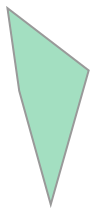

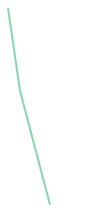

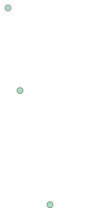

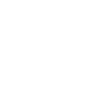

In [6]:
for x in projected_collection:
    display(Geometry(str(x)))